Question 1

Implement the de Waard-Milliams corrosion rate model with unit tests.


**De Waard-Milliams Corrosion Rate Model**

The de Waard-Milliams model is an empirical correlation that predicts the uniform CO2 corrosion rate of carbon steel in a sweet (CO2-containing, no H2S) environment, as a function of temperature, CO2 partial pressure, and pH. It's one of the earliest and most widely used corrosion-prediction models in the oil and gas industry, developed by Cees de Waard and collaborators (the 1975 model with Milliams, later extended by de Waard, Lotz and Dugstad into more sophisticated versions that add flow/shear-stress effects).

Formula

\begin{aligned}
\log_{10}(CR) &= 5.8 - \frac{1710}{T + 273.15} + 0.67 \log_{10}(P_{CO_2}) \\
CR_{corrected} &= CR \times 10^{-0.32(\text{pH} - 4.5)} \quad \text{(pH > 4.5 only)}
\end{aligned}


Where CR is the corrosion rate in mm/yr, T is temperature in °C, and P_CO2 is the CO2 partial pressure in bar.

**What each component does**

• 5.8 — the model's empirical intercept constant, fitted from lab and field corrosion data. It anchors the baseline log-rate before temperature and pressure effects are applied.

• 1710 / (T + 273.15) — the temperature term. T + 273.15 converts °C to Kelvin, matching the Arrhenius-type relationship the model is built on: corrosion is a temperature-activated chemical reaction, so this term grows smaller (less subtracted) as temperature rises, pushing the predicted rate up. It's the single biggest driver of the model's output.

• 0.67 * log10(P_CO2) — the CO2 partial pressure term. More dissolved CO2 means more carbonic acid available to attack the steel; the exponent (0.67) reflects that the relationship is sub-linear — doubling the CO2 pressure doesn't double the corrosion rate, it scales it more gently.

• 10 ** log_cr — converts the log-rate back to a linear corrosion rate in mm/yr, since the fitted relationship above is expressed in log space.

• pH correction 10^(-0.32 * (pH - 4.5)) — only triggers above pH 4.5. Below that, the water is considered acidic enough that no protective scale forms, so the uncorrected rate stands. Above 4.5, rising pH favours FeCO3 scale formation, which partially passivates the steel surface, so the model knocks the predicted rate down. The 0.32 exponent sets how steeply that protection scales with pH.

**• round(cr_mm_yr, 3) **— rounds the final answer to 3 decimal places, matching the precision the model's inputs can realistically support (it's an empirical correlation, not a first-principles calculation, so false precision beyond this is misleading).

In [ ]:
#de Waard Milliams corrosion rate code implementation

import math


def de_waard_milliams_corrosion_rate(
    temperature_c: float,
    co2_partial_pressure_bar: float,
    ph: float = 4.5,
) -> float:
    """Estimate CO2 corrosion rate using de Waard-Milliams model.

    Returns corrosion rate in mm/yr."""
    # Temperature factor
    log_cr = 5.8 - 1710 / (temperature_c + 273.15) + 0.67 * math.log10(co2_partial_pressure_bar)
    cr_mm_yr = 10 ** log_cr

    # pH correction (higher pH reduces rate)
    if ph > 4.5:
        cr_mm_yr *= 10 ** (-0.32 * (ph - 4.5))

    return round(cr_mm_yr, 3)


# Example: Usan conditions
if __name__ == "__main__":
    cr = de_waard_milliams_corrosion_rate(60, 2.5)
    print(f"Estimated corrosion rate: {cr} mm/yr")

Estimated corrosion rate: 8.586 mm/yr


In [ ]:
#unit tests

import unittest

# Since the function is already defined in the notebook, we can reference it directly
cr = de_waard_milliams_corrosion_rate


class TestDeWaardMilliams(unittest.TestCase):

    def test_usan_reference_case(self):
        # 60 C, 2.5 bar CO2, default pH 4.5 (no correction)
        self.assertAlmostEqual(cr(60, 2.5), 8.586, places=3)

    def test_default_ph_equals_4_5(self):
        # ph=4.5 explicitly must match the default (no correction applied)
        self.assertEqual(cr(60, 2.5), cr(60, 2.5, ph=4.5))

    def test_higher_ph_reduces_rate(self):
        self.assertLess(cr(60, 2.5, ph=6.0), cr(60, 2.5, ph=4.5))
        self.assertAlmostEqual(cr(60, 2.5, ph=6.0), 2.843, places=3)

    def test_lower_ph_has_no_effect(self):
        # correction only triggers above 4.5 (sweet/sour water below that is uncorrected)
        self.assertEqual(cr(60, 2.5, ph=3.0), cr(60, 2.5, ph=4.5))

    def test_higher_temperature_increases_rate(self):
        self.assertLess(cr(30, 2.5), cr(60, 2.5))
        self.assertLess(cr(60, 2.5), cr(90, 2.5))

    def test_higher_co2_pressure_increases_rate(self):
        self.assertLess(cr(60, 2.5), cr(60, 5.0))

    def test_returns_rounded_to_3dp(self):
        result = cr(60, 2.5)
        self.assertEqual(result, round(result, 3))

    def test_return_type_is_float(self):
        self.assertIsInstance(cr(60, 2.5), float)


if __name__ == "__main__":
    unittest.main(argv=['first-arg-is-ignored'], exit=False)

........
----------------------------------------------------------------------
Ran 8 tests in 0.007s

OK


**Question 2**

Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field.


In [8]:
"""
Synthetic 10-year hourly SCADA dataset generator for the Usan field.

Usan is a deepwater subsea development offshore Nigeria (~750 m water depth).
Parameter ranges below are set to be broadly realistic for that kind of
subsea oil production system (wellhead temperature, CO2 partial pressure,
pH, pressure, flow rate, water cut) -- they are illustrative, not measured
field data.

Includes:
- seasonal + diurnal cycles and slow multi-year trends (reservoir depletion,
  water cut rise)
- random planned/unplanned shutdown events (flow -> 0, pressure/temperature
  decay)
- random sensor dropout (NaN) to mimic real SCADA telemetry gaps
- a derived corrosion_rate_mm_yr column from the de Waard-Milliams model
  built earlier in this project
"""

import os
import numpy as np
import pandas as pd

RNG = np.random.default_rng(42)

START = "2016-01-01"
YEARS = 10
FREQ = "h"


def de_waard_milliams_corrosion_rate(temperature_c, co2_partial_pressure_bar, ph):
    """Vectorised de Waard-Milliams CO2 corrosion rate (mm/yr)."""
    log_cr = 5.8 - 1710 / (temperature_c + 273.15) + 0.67 * np.log10(co2_partial_pressure_bar)
    cr_mm_yr = 10 ** log_cr
    correction = np.where(ph > 4.5, 10 ** (-0.32 * (ph - 4.5)), 1.0)
    return np.round(cr_mm_yr * correction, 3)


def make_shutdown_mask(n_hours, rng):
    """Random planned + unplanned shutdown windows. Returns a 0/1 mask (1 = down)."""
    mask = np.zeros(n_hours, dtype=bool)

    # ~1 planned turnaround/year, 24-96 hrs
    for _ in range(YEARS):
        start = rng.integers(0, n_hours - 100)
        length = rng.integers(24, 96)
        mask[start:start + length] = True

    # unplanned trips: ~15/year, 2-20 hrs
    for _ in range(YEARS * 15):
        start = rng.integers(0, n_hours - 24)
        length = rng.integers(2, 20)
        mask[start:start + length] = True

    return mask


def add_dropout(series, rng, frac=0.01):
    """Randomly blank out `frac` of readings to mimic telemetry gaps."""
    out = series.copy()
    idx = rng.random(len(out)) < frac
    out[idx] = np.nan
    return out


def generate_usans_scada_dataset():
    timestamps = pd.date_range(START, periods=YEARS * 365 * 24, freq=FREQ)
    n = len(timestamps)
    t_years = np.arange(n) / (365 * 24)          # elapsed time in years, for trends
    hour_of_day = timestamps.hour.values
    day_of_year = timestamps.dayofyear.values

    shutdown = make_shutdown_mask(n, RNG)

    # --- Temperature (C): seasonal + diurnal cycle, mild noise ---
    temperature_c = (
        65
        + 4 * np.sin(2 * np.pi * day_of_year / 365)
        + 0.6 * np.sin(2 * np.pi * hour_of_day / 24)
        + RNG.normal(0, 0.8, n)
    )
    temperature_c = np.clip(temperature_c, 45, 85)

    # --- CO2 partial pressure (bar): slow drift as GOR/reservoir conditions change ---
    co2_partial_pressure_bar = 2.2 + 0.05 * t_years + RNG.normal(0, 0.12, n)
    co2_partial_pressure_bar = np.clip(co2_partial_pressure_bar, 1.0, 3.5)

    # --- pH: fairly stable, slight random walk ---
    ph = 4.8 + 0.15 * np.sin(2 * np.pi * t_years / 5) + RNG.normal(0, 0.1, n)
    ph = np.clip(ph, 4.0, 6.0)

    # --- Wellhead pressure (bar): declines over field life ---
    wellhead_pressure_bar = 210 - 6 * t_years + RNG.normal(0, 3, n)
    wellhead_pressure_bar = np.clip(wellhead_pressure_bar, 60, 230)

    # --- Flow rate (bbl/d): gentle decline curve + noise ---
    flow_rate_bbl_d = 42000 * np.exp(-0.03 * t_years) + RNG.normal(0, 800, n)
    flow_rate_bbl_d = np.clip(flow_rate_bbl_d, 0, None)

    # --- Water cut (%): rises as the field matures (logistic-ish growth) ---
    water_cut_pct = 10 + 45 / (1 + np.exp(-(t_years - 6)))
    water_cut_pct += RNG.normal(0, 1.0, n)
    water_cut_pct = np.clip(water_cut_pct, 5, 65)

    # --- Apply shutdowns ---
    flow_rate_bbl_d = np.where(shutdown, 0.0, flow_rate_bbl_d)
    wellhead_pressure_bar = np.where(shutdown, RNG.uniform(5, 15, n), wellhead_pressure_bar)
    # temperature decays toward ambient (~30C) during extended shutdowns
    temperature_c = np.where(shutdown, 30 + RNG.normal(0, 1.5, n), temperature_c)

    # --- Derived corrosion rate from the de Waard-Milliams model ---
    corrosion_rate_mm_yr = de_waard_milliams_corrosion_rate(
        temperature_c, co2_partial_pressure_bar, ph
    )

    df = pd.DataFrame({
        "timestamp": timestamps,
        "temperature_c": np.round(temperature_c, 2),
        "co2_partial_pressure_bar": np.round(co2_partial_pressure_bar, 3),
        "ph": np.round(ph, 2),
        "wellhead_pressure_bar": np.round(wellhead_pressure_bar, 1),
        "flow_rate_bbl_d": np.round(flow_rate_bbl_d, 0),
        "water_cut_pct": np.round(water_cut_pct, 2),
        "shutdown": shutdown.astype(int),
        "corrosion_rate_mm_yr": corrosion_rate_mm_yr,
    })

    # Sensor dropout on live process variables (not timestamp/shutdown flag)
    for col in ["temperature_c", "co2_partial_pressure_bar", "ph",
                "wellhead_pressure_bar", "flow_rate_bbl_d", "water_cut_pct"]:
        df[col] = add_dropout(df[col].values, RNG, frac=0.01)
        # corrosion rate can't be computed where its inputs are missing
    missing_inputs = df[["temperature_c", "co2_partial_pressure_bar", "ph"]].isna().any(axis=1)
    df.loc[missing_inputs, "corrosion_rate_mm_yr"] = np.nan

    return df


if __name__ == "__main__":
    df_sample = generate_usans_scada_dataset()
    os.makedirs("/mnt/user-data/outputs", exist_ok=True)
    df_sample.to_csv("/mnt/user-data/outputs/usan_scada_10yr_hourly.csv", index=False)

df = pd.read_csv("/mnt/user-data/outputs/usan_scada_10yr_hourly.csv")
display(df.head())

,timestamp,temperature_c,co2_partial_pressure_bar,ph,wellhead_pressure_bar,flow_rate_bbl_d,water_cut_pct,shutdown,corrosion_rate_mm_yr
0,2016-01-01 00:00:00,65.86,2.150,4.87,206.6,41015.0,10.45,0,7.229
1,2016-01-01 01:00:00,64.82,2.185,4.91,206.3,40957.0,10.97,0,6.874
2,2016-01-01 02:00:00,64.42,2.385,4.75,213.9,42784.0,9.65,0,8.077
3,2016-01-01 03:00:00,64.72,2.228,4.97,207.0,42933.0,NaN,0,6.609
4,2016-01-01 04:00:00,65.01,1.972,4.90,212.7,42158.0,10.30,0,6.512


Question 3

Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates.

In [11]:
"""
Usan field: synthetic SCADA data + PhysicsFeaturePipeline, end to end.

Self-contained for Colab: generates the 10-year hourly SCADA dataset,
runs it through the Extract -> Validate -> Physics Transform -> Feature
Store pipeline, computes monthly average corrosion rates, and writes
both output CSVs to the current working directory.

Pipeline physics transform covers corrosion rate (de Waard-Milliams)
and design envelope status fully; hydrate subcooling is a simplified,
illustrative correlation (a real one needs gas composition/specific
gravity, which this SCADA tag set doesn't carry); fatigue damage needs
cyclic stress data this dataset doesn't have, so it's left as a
flagged placeholder rather than faked.
"""

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

RNG_SEED = 42
START = "2016-01-01"
YEARS = 10


# ---------------------------------------------------------------- #
# 1. Synthetic raw SCADA data
# ---------------------------------------------------------------- #

def de_waard_milliams_corrosion_rate(temperature_c, co2_partial_pressure_bar, ph):
    """Vectorised de Waard-Milliams CO2 corrosion rate (mm/yr)."""
    log_cr = 5.8 - 1710 / (temperature_c + 273.15) + 0.67 * np.log10(co2_partial_pressure_bar)
    cr_mm_yr = 10 ** log_cr
    correction = np.where(ph > 4.5, 10 ** (-0.32 * (ph - 4.5)), 1.0)
    return np.round(cr_mm_yr * correction, 3)


def make_shutdown_mask(n_hours, rng):
    """Random planned + unplanned shutdown windows. Returns a 0/1 mask (1 = down)."""
    mask = np.zeros(n_hours, dtype=bool)
    for _ in range(YEARS):  # ~1 planned turnaround/year, 24-96 hrs
        start = rng.integers(0, n_hours - 100)
        length = rng.integers(24, 96)
        mask[start:start + length] = True
    for _ in range(YEARS * 15):  # unplanned trips: ~15/year, 2-20 hrs
        start = rng.integers(0, n_hours - 24)
        length = rng.integers(2, 20)
        mask[start:start + length] = True
    return mask


def add_dropout(series, rng, frac=0.01):
    """Randomly blank out `frac` of readings to mimic telemetry gaps."""
    out = series.copy()
    out[rng.random(len(out)) < frac] = np.nan
    return out


def generate_usan_scada():
    rng = np.random.default_rng(RNG_SEED)
    timestamps = pd.date_range(START, periods=YEARS * 365 * 24, freq="h")
    n = len(timestamps)
    t_years = np.arange(n) / (365 * 24)
    hour_of_day = timestamps.hour.values
    day_of_year = timestamps.dayofyear.values
    shutdown = make_shutdown_mask(n, rng)

    temperature_c = (65 + 4 * np.sin(2 * np.pi * day_of_year / 365)
                      + 0.6 * np.sin(2 * np.pi * hour_of_day / 24)
                      + rng.normal(0, 0.8, n))
    temperature_c = np.clip(temperature_c, 45, 85)

    co2_partial_pressure_bar = np.clip(2.2 + 0.05 * t_years + rng.normal(0, 0.12, n), 1.0, 3.5)
    ph = np.clip(4.8 + 0.15 * np.sin(2 * np.pi * t_years / 5) + rng.normal(0, 0.1, n), 4.0, 6.0)
    wellhead_pressure_bar = np.clip(210 - 6 * t_years + rng.normal(0, 3, n), 60, 230)
    flow_rate_bbl_d = np.clip(42000 * np.exp(-0.03 * t_years) + rng.normal(0, 800, n), 0, None)
    water_cut_pct = np.clip(10 + 45 / (1 + np.exp(-(t_years - 6))) + rng.normal(0, 1.0, n), 5, 65)

    flow_rate_bbl_d = np.where(shutdown, 0.0, flow_rate_bbl_d)
    wellhead_pressure_bar = np.where(shutdown, rng.uniform(5, 15, n), wellhead_pressure_bar)
    temperature_c = np.where(shutdown, 30 + rng.normal(0, 1.5, n), temperature_c)

    df = pd.DataFrame({
        "timestamp": timestamps,
        "temperature_c": np.round(temperature_c, 2),
        "co2_partial_pressure_bar": np.round(co2_partial_pressure_bar, 3),
        "ph": np.round(ph, 2),
        "wellhead_pressure_bar": np.round(wellhead_pressure_bar, 1),
        "flow_rate_bbl_d": np.round(flow_rate_bbl_d, 0),
        "water_cut_pct": np.round(water_cut_pct, 2),
        "shutdown": shutdown.astype(int),
    })

    for col in ["temperature_c", "co2_partial_pressure_bar", "ph",
                "wellhead_pressure_bar", "flow_rate_bbl_d", "water_cut_pct"]:
        df[col] = add_dropout(df[col].values, rng, frac=0.01)

    return df


# ---------------------------------------------------------------- #
# 2. Physics feature pipeline
# ---------------------------------------------------------------- #

class PhysicsFeaturePipeline(BaseEstimator, TransformerMixin):
    """Raw SCADA -> ML-ready physics-informed features.

    Stages: extract -> validate -> physics_transform -> feature_store.
    """

    DATA_DICTIONARY = {
        "temperature_c": (10, 95),
        "co2_partial_pressure_bar": (0.5, 4.0),
        "ph": (3.0, 7.0),
        "wellhead_pressure_bar": (0, 240),
        "flow_rate_bbl_d": (0, 50000),
        "water_cut_pct": (0, 100),
    }
    DESIGN_MAX_PRESSURE_BAR = 230
    DESIGN_MAX_TEMP_C = 90

    def extract(self, raw_df):
        cols = ["timestamp", "temperature_c", "co2_partial_pressure_bar", "ph",
                "wellhead_pressure_bar", "flow_rate_bbl_d", "water_cut_pct", "shutdown"]
        return raw_df[cols].copy()

    def validate(self, df):
        df = df.copy()
        for col, (lo, hi) in self.DATA_DICTIONARY.items():
            out_of_range = df[col].notna() & ~df[col].between(lo, hi)
            df[f"{col}_flag"] = np.select(
                [df[col].isna(), out_of_range], ["missing", "out_of_range"], default="ok"
            )
        return df

    def physics_transform(self, df):
        df = df.copy()

        df["corrosion_rate_mm_yr"] = de_waard_milliams_corrosion_rate(
            df["temperature_c"], df["co2_partial_pressure_bar"], df["ph"]
        )

        df["design_envelope_status"] = np.where(
            (df["wellhead_pressure_bar"] > self.DESIGN_MAX_PRESSURE_BAR)
            | (df["temperature_c"] > self.DESIGN_MAX_TEMP_C),
            "exceedance", "within",
        )

        # Hydrate subcooling (SIMPLIFIED, illustrative correlation only --
        # a real hydrate curve needs gas specific gravity/composition)
        hydrate_formation_c = 7.0 + 11.5 * np.log10(df["wellhead_pressure_bar"].clip(lower=1))
        df["hydrate_subcooling_c"] = (hydrate_formation_c - df["temperature_c"]).round(2)

        # Fatigue damage needs cyclic stress/strain data not present in this
        # tag set -- left as NaN rather than fabricated.
        df["fatigue_damage_index"] = np.nan

        return df

    def feature_store(self, df):
        return df  # raw measurements + physics-derived features, ready for ML

    def fit(self, X, y=None):
        return self

    def transform(self, raw_df):
        df = self.extract(raw_df)
        df = self.validate(df)
        df = self.physics_transform(df)
        df = self.feature_store(df)
        return df


# ---------------------------------------------------------------- #
# 3. Run it end to end
# ---------------------------------------------------------------- #

if __name__ == "__main__":
    raw = generate_usan_scada()

    pipeline = PhysicsFeaturePipeline()
    features = pipeline.transform(raw)

    flag_cols = [c for c in features.columns if c.endswith("_flag")]
    print("Validation flags (% of readings):")
    for c in flag_cols:
        print(" ", c, dict(features[c].value_counts(normalize=True).round(4)))
    print("\nDesign envelope exceedances:", (features["design_envelope_status"] == "exceedance").sum())
    print("Hydrate subcooling > 0 (risk) hours:", (features["hydrate_subcooling_c"] > 0).sum())

    monthly_avg = (
        features.set_index("timestamp")
        .resample("MS")["corrosion_rate_mm_yr"]
        .mean()
        .round(3)
        .rename("corrosion_rate_mm_yr_avg")
        .reset_index()
    )
    print(f"\n{len(monthly_avg)} months, overall mean: {monthly_avg['corrosion_rate_mm_yr_avg'].mean():.3f} mm/yr")

    features.to_csv("usan_scada_physics_features.csv", index=False)
    monthly_avg.to_csv("usan_monthly_corrosion_rate.csv", index=False)
    print("\nWrote usan_scada_physics_features.csv and usan_monthly_corrosion_rate.csv")

    # Auto-download if running in Colab
    try:
        from google.colab import files
        files.download("usan_scada_physics_features.csv")
        files.download("usan_monthly_corrosion_rate.csv")
    except ImportError:
        pass

Validation flags (% of readings):
  temperature_c_flag {'ok': np.float64(0.9895), 'missing': np.float64(0.0105)}
  co2_partial_pressure_bar_flag {'ok': np.float64(0.9901), 'missing': np.float64(0.0099)}
  ph_flag {'ok': np.float64(0.9896), 'missing': np.float64(0.0104)}
  wellhead_pressure_bar_flag {'ok': np.float64(0.9902), 'missing': np.float64(0.0098)}
  flow_rate_bbl_d_flag {'ok': np.float64(0.9898), 'missing': np.float64(0.0102)}
  water_cut_pct_flag {'ok': np.float64(0.9907), 'missing': np.float64(0.0093)}

Design envelope exceedances: 0
Hydrate subcooling > 0 (risk) hours: 0

120 months, overall mean: 8.039 mm/yr

Wrote usan_scada_physics_features.csv and usan_monthly_corrosion_rate.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Question 4

Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.


jumper  curr_wt_mm  t_min_mm  cr_mm_yr  rul_years risk_class
 J-001        11.2     12.25      0.15       0.00   Critical
 J-002        10.8     12.84      0.19       0.00   Critical
 J-003        11.5     11.09      0.12       3.46       High
 J-004         8.9      7.49      0.14      10.07        Low
 J-005        10.1     13.03      0.26       0.00   Critical
 J-006        11.0     11.96      0.17       0.00   Critical

Saved jumper_rul_results.csv and jumper_rul_chart.png


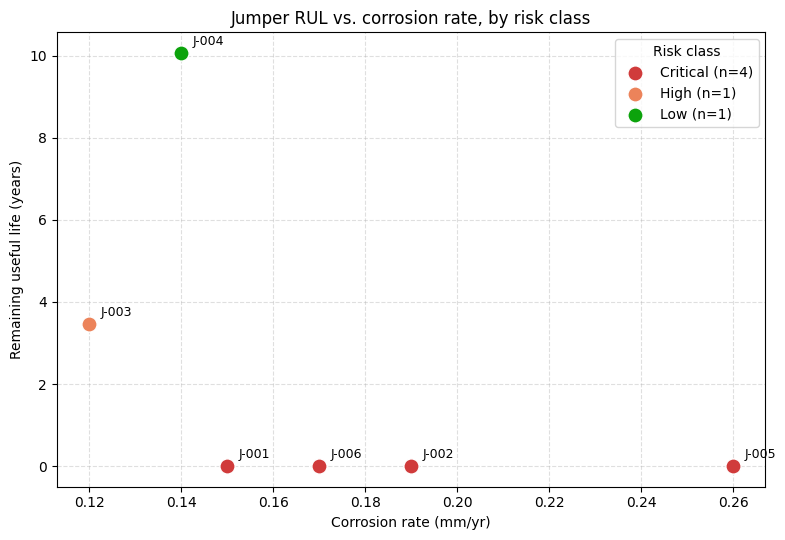

In [1]:
"""
Subsea jumper remaining useful life (RUL) from the case study data,
with a colour-coded risk-classification scatter plot.

Minimum required wall thickness uses Barlow's equation:
    t_min = P * D / (2 * SMYS * F)
ASSUMPTION (not given in the case study table): API 5L X65 pipe
(SMYS = 65,000 psi), offshore design factor F = 0.72. Swap these two
constants if your course material specifies a different grade/factor --
every RUL number below depends on them.
"""

import matplotlib.pyplot as plt
import pandas as pd

SMYS_PSI = 65000
DESIGN_FACTOR = 0.72

# --- Case study data ---
data = pd.DataFrame({
    "jumper": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
    "od_in": [10.75, 10.75, 10.75, 8.625, 10.75, 10.75],
    "orig_wt_mm": [12.7, 12.7, 12.7, 10.3, 12.7, 12.7],
    "curr_wt_mm": [11.2, 10.8, 11.5, 8.9, 10.1, 11.0],
    "cr_mm_yr": [0.15, 0.19, 0.12, 0.14, 0.26, 0.17],
    "p_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "t_c": [65, 72, 58, 55, 78, 68],
    "wc_pct": [32, 45, 28, 38, 62, 40],
})

# --- RUL calculation ---
data["t_min_mm"] = (data["p_psi"] * data["od_in"]) / (2 * SMYS_PSI * DESIGN_FACTOR) * 25.4
data["corrosion_allowance_remaining_mm"] = data["curr_wt_mm"] - data["t_min_mm"]
data["rul_years"] = (data["corrosion_allowance_remaining_mm"] / data["cr_mm_yr"]).clip(lower=0).round(2)


def risk_class(rul):
    if rul <= 2:
        return "Critical"
    elif rul <= 5:
        return "High"
    elif rul <= 10:
        return "Medium"
    else:
        return "Low"


data["risk_class"] = data["rul_years"].apply(risk_class)

RISK_COLORS = {"Critical": "#d03b3b", "High": "#ec835a", "Medium": "#fab219", "Low": "#0ca30c"}

print(data[["jumper", "curr_wt_mm", "t_min_mm", "cr_mm_yr", "rul_years", "risk_class"]]
      .round(2).to_string(index=False))

data.to_csv("jumper_rul_results.csv", index=False)

# --- Colour-coded chart ---
fig, ax = plt.subplots(figsize=(8, 5.5))

for risk, color in RISK_COLORS.items():
    subset = data[data["risk_class"] == risk]
    if not subset.empty:
        ax.scatter(subset["cr_mm_yr"], subset["rul_years"], s=120, color=color,
                   label=f"{risk} (n={len(subset)})", edgecolors="white", linewidths=1, zorder=3)

for _, row in data.iterrows():
    ax.annotate(row["jumper"], (row["cr_mm_yr"], row["rul_years"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)

ax.set_xlabel("Corrosion rate (mm/yr)")
ax.set_ylabel("Remaining useful life (years)")
ax.set_title("Jumper RUL vs. corrosion rate, by risk class")
ax.legend(title="Risk class", loc="upper right")
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig("jumper_rul_chart.png", dpi=150)
print("\nSaved jumper_rul_results.csv and jumper_rul_chart.png")